# Оценка живучести изолированной энергосети Дании

• **Сценарий моделирования:**
Дания топологически является «энергетическим островом», не имеющим сухопутных связей с другими странами. Вся стабильность зависит исключительно от внутреннего баланса.

• **Управляющий параметр:**
Изменяется температура T (внутренний технологический шум и отказы оборудования). 

• **Конкретная задача:**
- Найти критическую точку T_c. 
- Сравнить профиль фазового перехода сети с островной сетью Великобритании (Вариант 4) для выявления общих закономерностей «островных» топологий.

• **Ссылка на датасет:**
[Countries/Denmark/graphml/Denmark_highvoltage.graphml.](https://github.com/ComplexNetTSP/Power_grids/blob/master/Countries/Denmark/graphml/Denmark_highvoltage.graphml)

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


import networkx as nx

G = nx.read_graphml("../data/Denmark_highvoltage.graphml")
G

# Информация о графе

In [ ]:
comps = sorted(nx.connected_components(G), key=len, reverse=True)
LCC = G.subgraph(comps[0])                      # наибольшая компонента
N, M = G.number_of_nodes(), G.number_of_edges()
bridges = len(list(nx.bridges(G)))

print(f"Узлов: {N}, рёбер: {M}")
print(f"Средняя степень <k>: {2 * M / N:.2f}, максимальная: {max(k for _, k in G.degree())}")
print(f"Компонент связности: {len(comps)}, размеры: {[len(c) for c in comps]}")
print(f"Мостов: {bridges} из {M} ({bridges / M:.0%})")
print(f"Независимых циклов: {M - N + len(comps)}")
print(f"Диаметр (наибольшая компонента): {nx.diameter(LCC)}")
print(f"Средняя кластеризация: {nx.average_clustering(G):.3f}")



Узлов: 96, рёбер: 105
Средняя степень <k>: 2.19, максимальная: 5
Компонент связности: 2, размеры: [63, 33]
Мостов: 72 из 105 (69%)
Независимых циклов: 11
Диаметр (наибольшая компонента): 27
Средняя кластеризация: 0.071


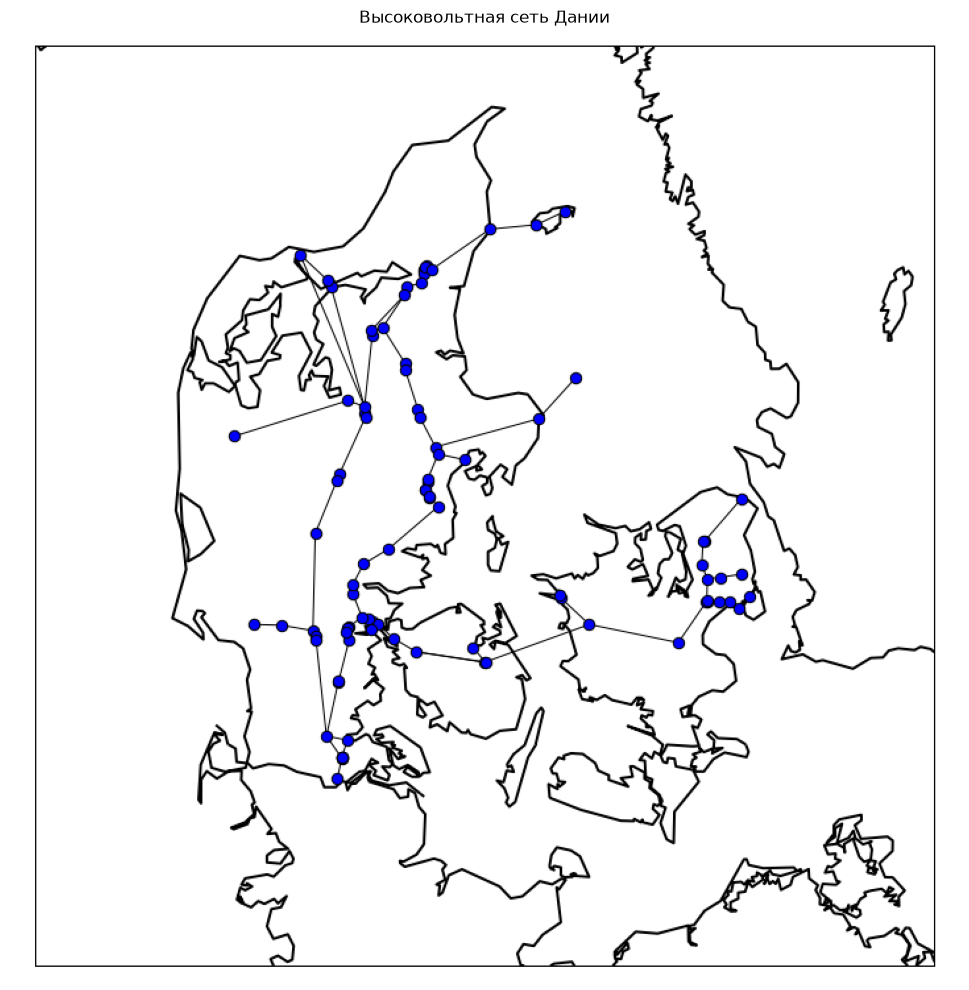

In [27]:
image = plt.imread('Denmark_highvoltage.png')


fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(image)
ax.set_title('Высоковольтная сеть Дании')
ax.axis('off')          
plt.tight_layout()
plt.show()